# Trees - Data Science Portfolio -

# Introduction
**Dataset:** Drug classification data (200 patients) 

**Target variable:** Drug prescribed (5 classes, imbalanced: drugY 45.5%, drugX 27%, drugA 11.5%, drugC 8%, drugB 8%)

**Features:** Age, Sex, blood pressure (BP), Cholesterol and the sodium-to-potassium ratio (Na_to_K)

**Techniques applied:** Decision tree classifier (scikit-learn), label and ordinal encoding, pre-pruning by tuning max_depth, cost-complexity pruning (ccp_alpha), learning curves, class-imbalance resampling (RandomOverSampler, SMOTE, RandomUnderSampler), and a custom bagging ensemble compared with scikit-learn's RandomForestClassifier

A decision tree classifies a sample by recursively splitting the data on feature thresholds. At each node it picks the split that gives the lowest weighted Gini impurity, and each leaf predicts the majority class.

In this notebook, I will:

* Explore the data (no missing values, mostly categorical features, large class imbalance) and encode the categorical columns
* Split the data into a stratified 80/20 train/test set (160/40 samples)
* Tune max_depth to control overfitting (best depth = 4), check cost-complexity pruning (best ccp_alpha = 0, so no extra pruning was needed), and use a learning curve to confirm the train and CV accuracy converge
* Evaluate the pruned tree on the test set: 97.5% accuracy (39/40 correct) and 0.933 balanced accuracy, with a classification report and confusion matrix
* Identify which features matter most (Na_to_K 0.48, BP 0.27, Age 0.14, Cholesterol 0.12, Sex 0.00); the tree's first split is Na_to_K ≤ 14.839, which sends high-ratio patients straight to drugY
* Find the only error: one drugB patient predicted as drugA (drugB recall 0.67 on just 3 test samples)
* Test three resampling strategies; none changed accuracy (0.975) or balanced accuracy (0.933), so the single error comes from feature overlap between drugA and drugB, not from class imbalance
* Build a custom bagging ensemble on SMOTE-resampled data and compare it with scikit-learn's RandomForest (97.5% test accuracy, 0.997 OOB score); the custom ensemble with 3 features per tree stabilises at ~0.975 after roughly 40-50 trees

In [1]:
import pandas as pd
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
 
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    classification_report, ConfusionMatrixDisplay
)
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

RNG = np.random.default_rng(42)

In [2]:
df = pd.read_csv("datasets/trees_data.csv")
df

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY
...,...,...,...,...,...,...
195,56,F,LOW,HIGH,11.567,drugC
196,16,M,LOW,HIGH,12.006,drugC
197,52,M,NORMAL,HIGH,9.894,drugX
198,23,M,NORMAL,NORMAL,14.020,drugX


# Exploratory Data analysis

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    object 
 2   BP           200 non-null    object 
 3   Cholesterol  200 non-null    object 
 4   Na_to_K      200 non-null    float64
 5   Drug         200 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 9.5+ KB


There's no null, and most are categorical values, which we will encoded  (except age and Na_to_K).

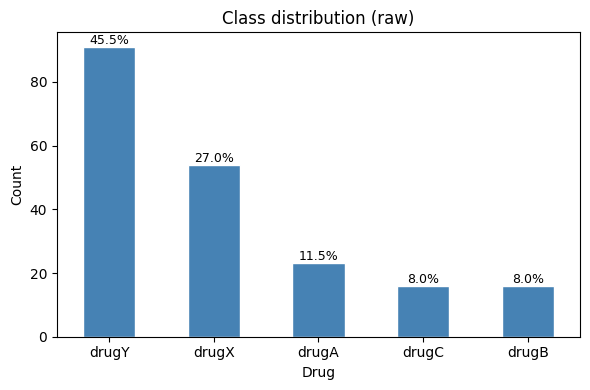


Class counts:
 Drug
drugY    91
drugX    54
drugA    23
drugC    16
drugB    16
Name: count, dtype: int64


In [4]:
fig, ax = plt.subplots(figsize=(6, 4))

class_counts = df["Drug"].value_counts()
class_counts.plot(kind="bar", ax=ax, color="steelblue", edgecolor="white")
ax.set_title("Class distribution (raw)")
ax.set_xlabel("Drug")
ax.set_ylabel("Count")
ax.tick_params(axis="x", rotation=0)

for i, v in enumerate(class_counts):
    ax.text(i, v + 1, f"{v/len(df)*100:.1f}%", ha="center", fontsize=9)

plt.tight_layout()
plt.show()
print("\nClass counts:\n", class_counts)

There's a large class imbalance, which we will address later in the notebook.

### Encoding

In [5]:
le = LabelEncoder()

categorical_cols = ['Sex','BP','Cholesterol','Drug']

df_encoded = df.copy()

# Fit a dedicated encoder only for the target variable
le = LabelEncoder()
df_encoded['Drug'] = le.fit_transform(df_encoded['Drug'])

# Encode other categoricals separately without overwriting le

oe = OrdinalEncoder()
df_encoded[['Sex', 'BP', 'Cholesterol']] = oe.fit_transform(df_encoded[['Sex', 'BP', 'Cholesterol']])

In [6]:
print("\nEncoded classes:", list(zip(le.classes_, le.transform(le.classes_))))
print("Encoded columns:", df_encoded.columns.tolist())


Encoded classes: [('drugA', np.int64(0)), ('drugB', np.int64(1)), ('drugC', np.int64(2)), ('drugX', np.int64(3)), ('drugY', np.int64(4))]
Encoded columns: ['Age', 'Sex', 'BP', 'Cholesterol', 'Na_to_K', 'Drug']


# Decision tree & pruning

In [7]:
df = df_encoded.copy()

X = df.drop(columns=['Drug'])
y = df['Drug']

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"\nTrain: {len(X_train)} \nTest: {len(X_test)}")


Train: 160 
Test: 40


## Depth

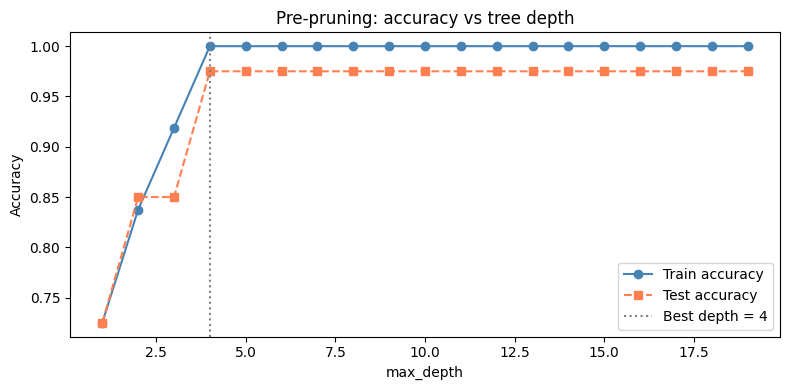

Best max_depth by test accuracy: 4


In [9]:
depths = range(1, 20)
train_accs, test_accs = [], []
 
for d in depths:
    clf = DecisionTreeClassifier(criterion="gini", max_depth=d, random_state=42)
    clf.fit(X_train, y_train)
    train_accs.append(accuracy_score(y_train, clf.predict(X_train)))
    test_accs.append(accuracy_score(y_test, clf.predict(X_test)))
 
plt.figure(figsize=(8, 4))
plt.plot(depths, train_accs, "o-", label="Train accuracy", color="steelblue")
plt.plot(depths, test_accs, "s--", label="Test accuracy", color="coral")
plt.axvline(x=test_accs.index(max(test_accs)) + 1, color="gray",
            linestyle=":", label=f"Best depth = {test_accs.index(max(test_accs)) + 1}")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Pre-pruning: accuracy vs tree depth")
plt.legend()
plt.tight_layout()
plt.show()
 
best_depth = test_accs.index(max(test_accs)) + 1
print(f"Best max_depth by test accuracy: {best_depth}")
 

At depths < 4, both train and test accuracy are low a  the model is too simple to capture the decision boundaries (underfitting). Accuracy for both depth and train plateued at depth = 4. As such, we will use that as our depth.

## Cost-complexity pruning (ccp_alpha) 

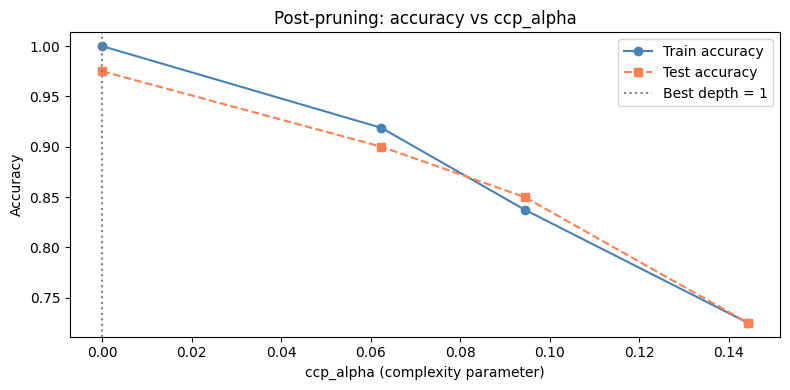

Best ccp_alpha: 0.00000


In [10]:
full_tree = DecisionTreeClassifier(criterion="gini", random_state=42)
path = full_tree.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas[:-1]  # exclude the trivial root-only tree
 
train_accs_ccp, test_accs_ccp = [], []
for alpha in ccp_alphas:
    clf = DecisionTreeClassifier(criterion="gini", ccp_alpha=alpha, random_state=42)
    clf.fit(X_train, y_train)
    train_accs_ccp.append(accuracy_score(y_train, clf.predict(X_train)))
    test_accs_ccp.append(accuracy_score(y_test, clf.predict(X_test)))
 
plt.figure(figsize=(8, 4))
plt.plot(ccp_alphas, train_accs_ccp, "o-", label="Train accuracy", color="steelblue")
plt.plot(ccp_alphas, test_accs_ccp, "s--", label="Test accuracy", color="coral")
plt.xlabel("ccp_alpha (complexity parameter)")
plt.ylabel("Accuracy")
plt.title("Post-pruning: accuracy vs ccp_alpha")
plt.axvline(x=test_accs_ccp.index(max(test_accs_ccp)), color="gray",
            linestyle=":", label=f"Best depth = {test_accs_ccp.index(max(test_accs_ccp)) + 1}")
plt.legend()
plt.tight_layout()
plt.show()
 
best_alpha = ccp_alphas[test_accs_ccp.index(max(test_accs_ccp))]
print(f"Best ccp_alpha: {best_alpha:.5f}")
 

## Learning curve

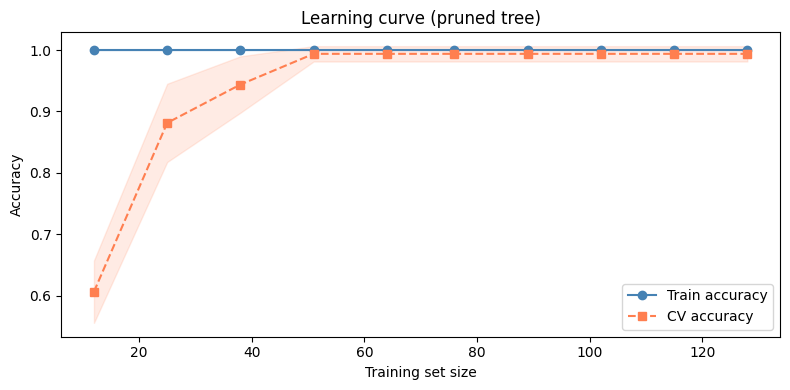

In [11]:
train_sizes, train_scores, test_scores = learning_curve(
    DecisionTreeClassifier(max_depth=best_depth, ccp_alpha=best_alpha, random_state=42),
    X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5, scoring="accuracy"
)

train_mean = train_scores.mean(axis=1)
test_mean  = test_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
test_std   = test_scores.std(axis=1)

plt.figure(figsize=(8, 4))
plt.plot(train_sizes, train_mean, "o-", color="steelblue", label="Train accuracy")
plt.plot(train_sizes, test_mean,  "s--", color="coral",    label="CV accuracy")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color="steelblue")
plt.fill_between(train_sizes, test_mean  - test_std,  test_mean  + test_std,  alpha=0.15, color="coral")
plt.xlabel("Training set size")
plt.ylabel("Accuracy")
plt.title("Learning curve (pruned tree)")
plt.legend()
plt.tight_layout()
plt.show()

As training set size increases, train and test accuracy converge toward each other. By 60 samples the two curves have fully converged and the shaded variance band on CV accuracy collapses, indicating the model is neither overfitting nor underfitting at the full training size.

## Final tree

In [12]:
best_tree = DecisionTreeClassifier(
    criterion="gini", max_depth=best_depth, ccp_alpha=best_alpha, random_state=42
)
best_tree.fit(X_train, y_train)
y_pred_tree = best_tree.predict(X_test)
 
print(classification_report(y_test, y_pred_tree, target_names=le.classes_))
 


              precision    recall  f1-score   support

       drugA       0.83      1.00      0.91         5
       drugB       1.00      0.67      0.80         3
       drugC       1.00      1.00      1.00         3
       drugX       1.00      1.00      1.00        11
       drugY       1.00      1.00      1.00        18

    accuracy                           0.97        40
   macro avg       0.97      0.93      0.94        40
weighted avg       0.98      0.97      0.97        40



DrugC, drugX, and drugY all score perfect precision, recall, and F1. However, drugB has a recall of 0.67 means the model missed 1 out of 3 drugB patients, classifying them as something else. With only 3 support samples in the test set, this is partly a small sample problem rather than a fundamental model failure.

drugA has lower precision (0.83), meaning one false positive, meaning something got predicted as drugA when it wasn't. 


The class imblance may explain this result as drugB and drugC have far fewer training examples than drugY (47%).

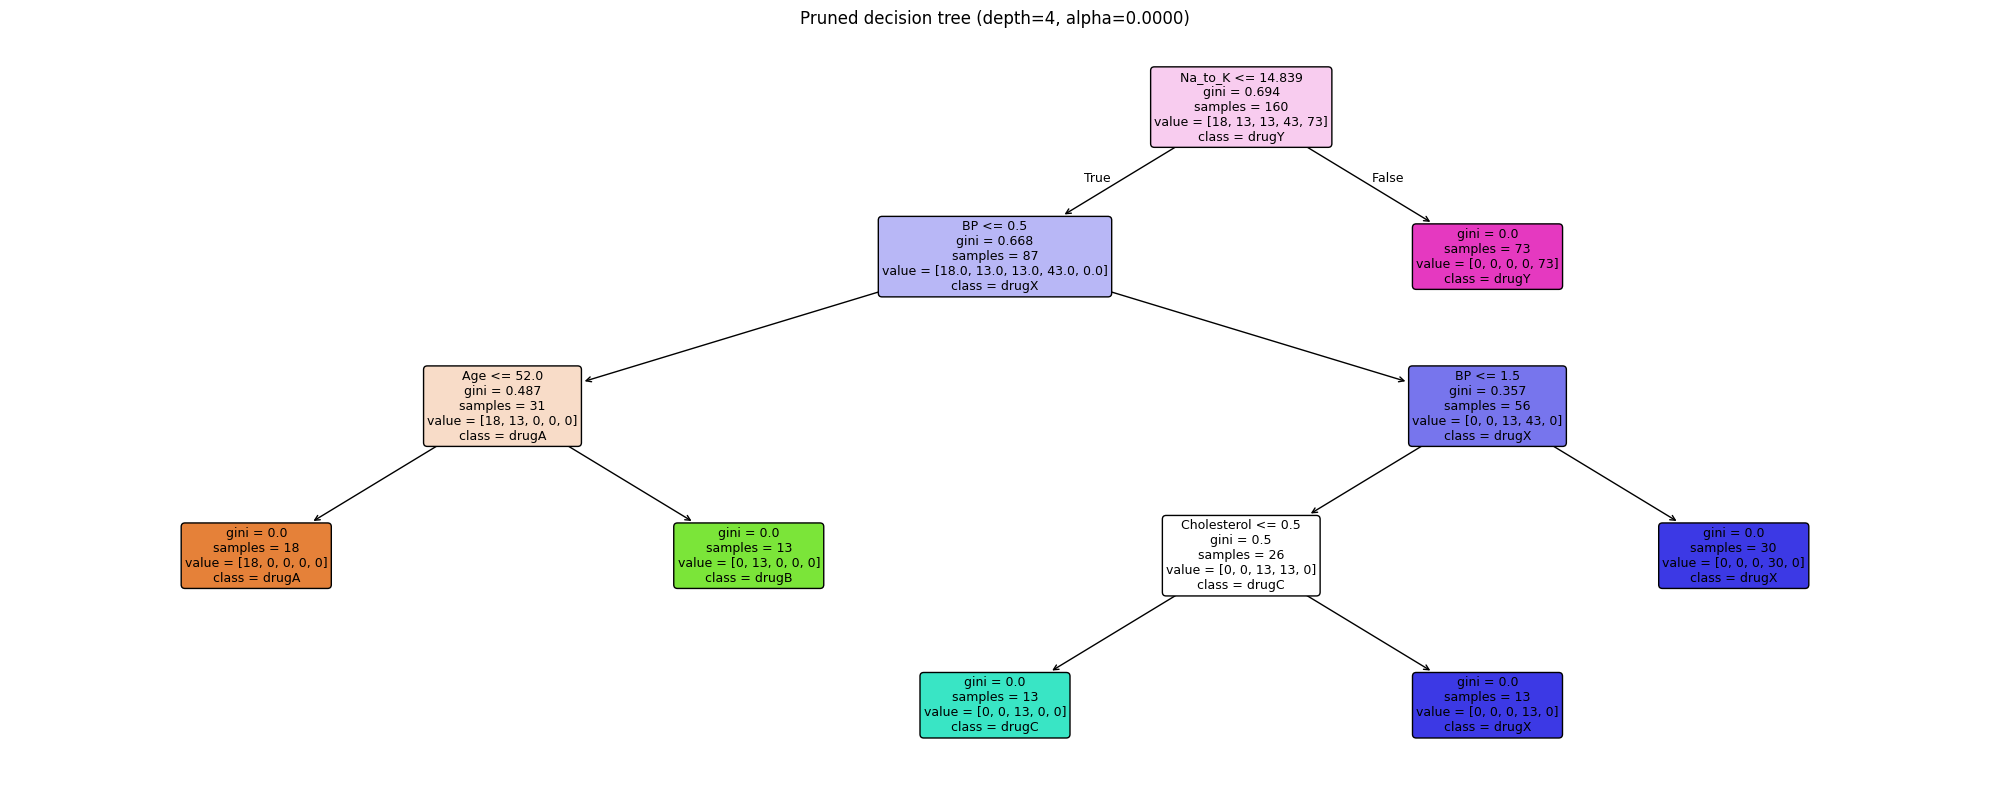

In [13]:
# Visualise the tree
plt.figure(figsize=(20, 8))
plot_tree(
    best_tree, feature_names=X.columns, class_names=le.classes_,
    filled=True, rounded=True, fontsize=9
)
plt.title(f"Pruned decision tree (depth={best_depth}, alpha={best_alpha:.4f})")
plt.tight_layout()
plt.show()
 

The tree first splits on Na_to_K ≤ 14.839. Patients with a high ratio (>14.839) are immediately classified as drugY with gini=0.0. This confirms Na_to_K is the dominant feature. For patients with lower Na_to_K, the tree then uses blood pressure and age to separate the remaining drug classes. drugA is assigned to younger patients (Age ≤ 52) with low BP, drugB to older low-BP patients, and drugC vs drugX is resolved by cholesterol level.

Despite max_depth=4, the tree found pure leaf nodes (gini=0.0) at depth 2 on the right branch and depth 3 on several left branches. The pruning didn't need to cut much because the data is naturally well-separated.

The fact that every leaf has gini=0.0 is worth flagging as on a small dataset this could indicate the tree has memorised the training data, risking overfitting. However, the max_depth and ccp values are choose keeping the overfitting risk in mind, and later in the learning curve section, we see that the data is not overfitted.

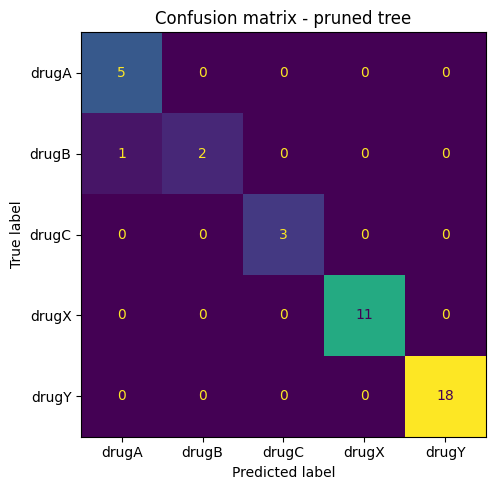

In [14]:
# Confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_tree, display_labels=le.classes_, ax=ax, colorbar=False
)
ax.set_title("Confusion matrix - pruned tree")
plt.tight_layout()
plt.show()

The diagonal is nearly perfect 5+2+3+11+18 = 39 out of 40 correct (97% accuracy). Every drug class lands on the diagonal except one case.

The single misclassification is the 1 in the drugB row, drugA column as one drugB patient was predicted as drugA. This is the recall=0.67 for drugB  saw in the report. These two drugs are likely the most similar in feature space (probably overlapping age/BP/cholesterol combinations without a strong Na_to_K signal to separate them).

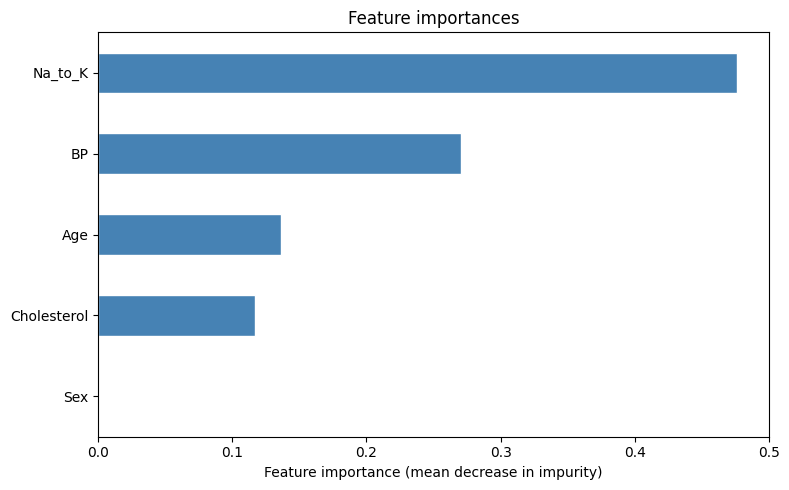


Top 5 features:
Na_to_K        0.476235
BP             0.270641
Age            0.136007
Cholesterol    0.117117
Sex            0.000000
dtype: float64


In [15]:
importances = pd.Series(best_tree.feature_importances_, index=X.columns).sort_values(ascending=True)
 
plt.figure(figsize=(8, 5))
importances.plot(kind="barh", color="steelblue", edgecolor="white")
plt.xlabel("Feature importance (mean decrease in impurity)")
plt.title("Feature importances")
plt.tight_layout()
plt.show()
 
print("\nTop 5 features:")
print(importances.sort_values(ascending=False).head())
 


As expected, Na_to_K ratio is the most import feature in the classification of the provided drugs.

# Class imbalance & resampling


Original class distribution:
 Drug
4    73
3    43
0    18
2    13
1    13
Name: count, dtype: int64


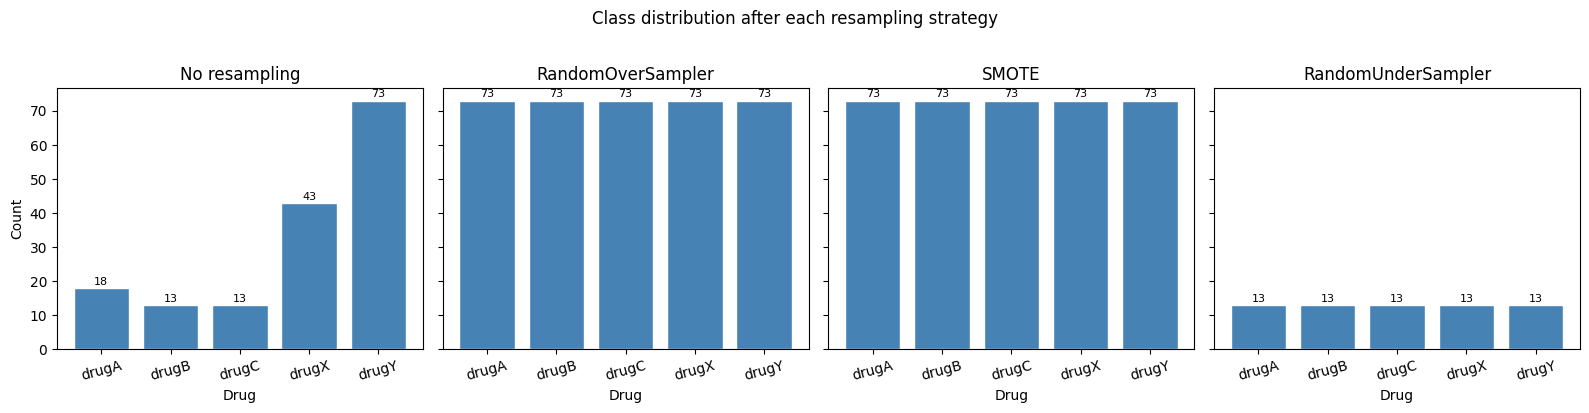

In [16]:
# drugY accounts for ~47% of samples. We compare three resampling strategies
# and evaluate using balanced_accuracy_score to avoid flattering the majority.
 
print("\nOriginal class distribution:\n", pd.Series(y_train).value_counts())
 
strategies = {
    "No resampling": (X_train, y_train),
    "RandomOverSampler": RandomOverSampler(random_state=42).fit_resample(X_train, y_train),
    "SMOTE": SMOTE(random_state=42, k_neighbors=3).fit_resample(X_train, y_train),
    "RandomUnderSampler": RandomUnderSampler(random_state=42).fit_resample(X_train, y_train),
}

# Class distribution before and after each resampling strategy
fig, axes = plt.subplots(1, len(strategies), figsize=(16, 4), sharey=True)

for ax, (name, (X_res, y_res)) in zip(axes, strategies.items()):
    counts = pd.Series(y_res).value_counts().sort_index()
    ax.bar([le.classes_[i] for i in counts.index], counts.values, 
           color="steelblue", edgecolor="white")
    ax.set_title(name)
    ax.set_xlabel("Drug")
    ax.tick_params(axis="x", rotation=15)
    for i, v in enumerate(counts.values):
        ax.text(i, v + 1, str(v), ha="center", fontsize=8)

axes[0].set_ylabel("Count")
plt.suptitle("Class distribution after each resampling strategy", y=1.02)
plt.tight_layout()
plt.show()
 

In [17]:
results = {}
for name, (X_res, y_res) in strategies.items():
    clf = DecisionTreeClassifier(criterion="gini", max_depth=best_depth, random_state=42)
    clf.fit(X_res, y_res)
    preds = clf.predict(X_test)
    results[name] = {
        "accuracy": accuracy_score(y_test, preds),
        "balanced_accuracy": balanced_accuracy_score(y_test, preds),
        "train_size": len(y_res),
        "class_counts": pd.Series(y_res).value_counts().to_dict(),
    }
    print(f"\n{name}: acc={results[name]['accuracy']:.3f} | "
          f"balanced_acc={results[name]['balanced_accuracy']:.3f} | "
          f"train_size={results[name]['train_size']}")


No resampling: acc=0.975 | balanced_acc=0.933 | train_size=160

RandomOverSampler: acc=0.975 | balanced_acc=0.933 | train_size=365

SMOTE: acc=0.975 | balanced_acc=0.933 | train_size=365

RandomUnderSampler: acc=0.975 | balanced_acc=0.933 | train_size=65


Resampling to address class imbalance does not improve the model.

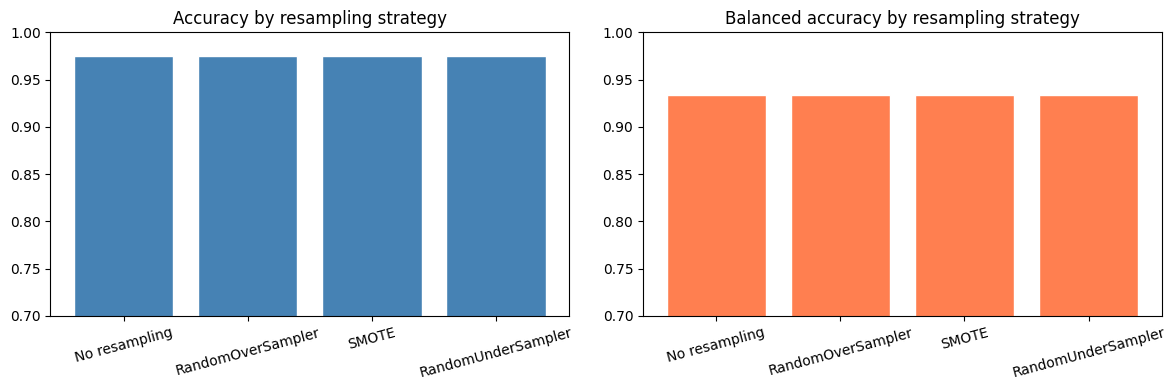

In [18]:
# Bar chart comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
names = list(results.keys())
accs = [results[n]["accuracy"] for n in names]
bal_accs = [results[n]["balanced_accuracy"] for n in names]
 
axes[0].bar(names, accs, color="steelblue", edgecolor="white")
axes[0].set_ylim(0.7, 1.0)
axes[0].set_title("Accuracy by resampling strategy")
axes[0].tick_params(axis="x", rotation=15)
 
axes[1].bar(names, bal_accs, color="coral", edgecolor="white")
axes[1].set_ylim(0.7, 1.0)
axes[1].set_title("Balanced accuracy by resampling strategy")
axes[1].tick_params(axis="x", rotation=15)
 
plt.tight_layout()
plt.show()

All four strategies produce equivalent accuracy (~0.975) and balanced accuracy (~0.933). This suggests the class imbalance in this dataset does not significantly impair model performance the feature Na_to_K provides such a strong signal that even minority classes (drugB, drugC) are well-separated. Resampling is most beneficial when the model is confusing minority classes with the majority; here, the single misclassification (drugB→drugA) persists across all strategies, indicating it is caused by feature overlap between those two classes rather than insufficient minority class representation.

# Ensemble

Although resampling did not improve the single decision tree's accuracy, we still apply SMOTE before building the ensemble. Ensemble methods aggregate many trees, each trained
on a bootstrap sample. Without resampling, minority classes (drugB, drugC) may be under-represented in several bootstrap draws, introducing variance in how well those classes are learned across trees. SMOTE equalises class frequencies before bootstrapping, ensuring every tree has a fair chance of seeing all classes.

In [19]:
# manual_bagging: train n_estimators trees on bootstrap samples,
# aggregate predictions by majority vote.
# Returns cumulative test accuracies (one per added tree) and final predictions.

def manual_bagging(X_tr, y_tr, X_te, n_estimators=50, max_features=None,
                   max_depth=None, random_state=42):
    rng = np.random.default_rng(random_state)
    n_samples = len(X_tr)
    n_features = X_tr.shape[1]
    if max_features is None:
        max_features = n_features
    elif max_features == "sqrt":
        max_features = int(np.sqrt(n_features))

    all_preds = []
    cumulative_accs = []

    X_tr_arr = X_tr.values if hasattr(X_tr, "values") else X_tr
    X_te_arr = X_te.values if hasattr(X_te, "values") else X_te
    y_tr_arr = y_tr.values if hasattr(y_tr, "values") else y_tr

    for i in range(n_estimators):
        # Bootstrap sample (sample with replacement)
        idx = rng.integers(0, n_samples, size=n_samples)
        X_boot, y_boot = X_tr_arr[idx], y_tr_arr[idx]

        # Random feature subset per tree — controls model complexity
        feat_idx = rng.choice(n_features, size=max_features, replace=False)

        clf = DecisionTreeClassifier(max_depth=max_depth,
                                     random_state=int(rng.integers(1e6)))
        clf.fit(X_boot[:, feat_idx], y_boot)

        preds = clf.predict(X_te_arr[:, feat_idx])
        all_preds.append(preds)

        # Majority vote across all trees so far
        stacked = np.stack(all_preds, axis=1)
        majority = np.apply_along_axis(
            lambda x: np.bincount(x, minlength=len(le.classes_)).argmax(),
            1, stacked
        )
        cumulative_accs.append(accuracy_score(y_te, majority))

    return cumulative_accs, majority

# Use SMOTE-resampled data for the ensemble
X_tr_res, y_tr_res = SMOTE(random_state=42, k_neighbors=3).fit_resample(X_train, y_train)
y_te = y_test.values

# Run manual bagging with two feature strategies
# We use max_features=3 (majority of features) for a meaningful comparison.
accs_all_feat, _ = manual_bagging(X_tr_res, y_tr_res, X_test,
                                   n_estimators=100, max_features=None,
                                   max_depth=best_depth)

accs_sqrt_feat, final_preds = manual_bagging(X_tr_res, y_tr_res, X_test,
                                              n_estimators=100, max_features=3,
                                              max_depth=best_depth)

rf = RandomForestClassifier(n_estimators=100, max_features=3,
                             max_depth=best_depth, random_state=42, oob_score=True)
rf.fit(X_tr_res, y_tr_res)
rf_acc = accuracy_score(y_test, rf.predict(X_test))
print(f"Sklearn RandomForest accuracy: {rf_acc:.3f} | OOB score: {rf.oob_score_:.3f}")

Sklearn RandomForest accuracy: 0.975 | OOB score: 0.997


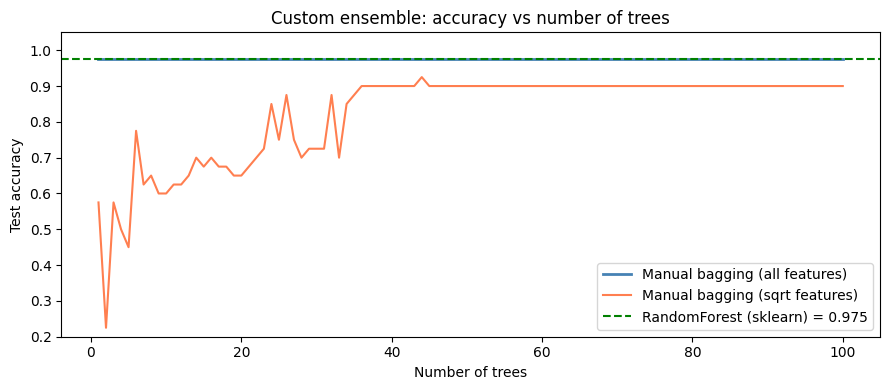

In [20]:
# Plot accuracy vs number of trees for both strategies
n_range = range(1, 101)

plt.figure(figsize=(9, 4))
plt.plot(list(n_range), accs_all_feat,
         label="Manual bagging (all features)", color="steelblue", linewidth=2)
plt.plot(list(n_range), accs_sqrt_feat,
         label="Manual bagging (sqrt features)", color="coral", linewidth=1.5)
plt.axhline(rf_acc, color="green", linestyle="--",
            label=f"RandomForest (sklearn) = {rf_acc:.3f}")
plt.xlabel("Number of trees")
plt.ylabel("Test accuracy")
plt.title("Custom ensemble: accuracy vs number of trees")
plt.ylim(0.2, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

Munual bagging with squared features (3-features variant) started rough but around ~40–50 trees, it starts to stablise at ~0.975, taking longer to converge. This is expected as restricting each tree to 3 out of 5 features means some bootstrap trees will miss Na_to_K, the dominant predictor. 